# Route D: redox in endocycling fly cells (salivary glands GSE121956; induced endocycles in S2 cells GSE121955)

Pick the dataset in Cell 1, then **Runtime → Run all**. Data download from GEO into *Colab Notebooks/route_d_salivary*. Run once per dataset.

In [ ]:
#@title Cell 1 - Settings and connect Google Drive
import gzip, io, os, re, subprocess, tarfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:
    display = print

#@markdown **GSE121956**: salivary glands (endocycling) vs brain and imaginal discs (dividing), feeding 3rd-instar larvae.
#@markdown **GSE121955**: S2 cells pushed into endocycles by Cyclin A or Myb knockdown vs GFP-knockdown controls.
GSE = "GSE121956"  #@param ["GSE121956", "GSE121955"]
DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/route_d_salivary"  #@param {type:"string"}
GTF_PATH = "/content/drive/MyDrive/Colab Notebooks/route_b_fly/Drosophila_melanogaster.gtf.gz"  #@param {type:"string"}
N_RANDOM_SETS = 2000  #@param {type:"integer"}
SEED = 1  #@param {type:"integer"}
DATA_DIR = os.environ.get("ROUTE_D_DATA", DATA_DIR)
GTF_PATH = os.environ.get("ROUTE_D_GTF", GTF_PATH)
if DATA_DIR.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
GDIR = os.path.join(DATA_DIR, GSE)
os.makedirs(GDIR, exist_ok=True)
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 14); pd.set_option("display.max_rows", 200)


class StopHere(Exception):
    """Stops the notebook with a plain-language message."""


# Which samples are endocycling ("test") and which are dividing ("reference"), recognised from the GEO descriptions
GROUP_RULES = {
    "GSE121956": [("salivary gland", r"(?i:salivary)|(?<![A-Za-z])SG(?![a-z])", "test"),
                  ("brain + imaginal disc", r"(?i:brain|disc|disk|wing|eye)|(?<![A-Za-z])BD(?![a-z])", "reference")],
    "GSE121955": [("CycA knockdown", r"(?i:cyc\s*-?\s*a|cyclin\s*a)", "test"), ("Myb knockdown", r"(?i:myb)", "test"),
                  ("GFP control", r"(?i:gfp|control)", "reference")],
}
print("Dataset:", GSE, "| folder:", GDIR)

Mounted at /content/drive
Dataset: GSE121956 | folder: /content/drive/MyDrive/Colab Notebooks/route_d_salivary/GSE121956


In [ ]:
#@title Cell 2 - Download from GEO (sample descriptions and the expression files)
BASE = os.environ.get("ROUTE_D_GEO", "https://ftp.ncbi.nlm.nih.gov/geo")


def fetch(url, dest):
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        print(f"   already here: {os.path.basename(dest)}"); return True
    r = subprocess.run(["curl", "-fsSL", "-m", "3600", "-o", dest + ".part", url], capture_output=True, text=True)
    if r.returncode != 0:
        if os.path.exists(dest + ".part"): os.remove(dest + ".part")
        return False
    os.replace(dest + ".part", dest)
    print(f"   downloaded {os.path.basename(dest)} ({os.path.getsize(dest) / 1e6:.1f} MB)"); return True


def listing(url):
    r = subprocess.run(["curl", "-fsSL", "-m", "120", url], capture_output=True, text=True)
    return [h for h in re.findall(r'href="([^"?/][^"]*)"', r.stdout) if not h.startswith("http")] if r.returncode == 0 else []


stub = GSE[:-3] + "nnn"
mdir, sdir = f"{BASE}/series/{stub}/{GSE}/matrix/", f"{BASE}/series/{stub}/{GSE}/suppl/"
matrices = [os.path.join(GDIR, n) for n in ([h for h in listing(mdir) if h.endswith("_series_matrix.txt.gz")]
                                           or [f"{GSE}_series_matrix.txt.gz"]) if fetch(mdir + n, os.path.join(GDIR, n))]
if not matrices:
    raise StopHere(f"Could not download the sample descriptions from {mdir}. Check GEO opens in your browser, then run again.")
suppl = [h for h in listing(sdir) if not h.endswith("/")]
print("Supplementary files on GEO:", suppl or "none listed")
got = [os.path.join(GDIR, n) for n in suppl if fetch(sdir + n, os.path.join(GDIR, n))]
if not got:   # GEO listing failed this time: use files downloaded on an earlier run
    got = [os.path.join(GDIR, n) for n in sorted(os.listdir(GDIR))
           if n.startswith(GSE) and "series_matrix" not in n and not n.endswith(".part")
           and re.search(r"\.(tar|txt|tsv|csv|tab|xlsx?)(\.gz)?$", n, re.I)]
    if got:
        print("Using files already in your folder:", [os.path.basename(g) for g in got])
if not got:
    raise StopHere("No expression files could be downloaded. Send me this message and the list above.")
if not os.path.exists(GTF_PATH):
    raise StopHere(f"Gene annotation not found at {GTF_PATH}. It is the same file used in Route B; fix GTF_PATH in Cell 1.")

   already here: GSE121956_series_matrix.txt.gz
Supplementary files on GEO: ['GSE121956_GSF1939_SG_RNAseq_raw_counts.xlsx.gz', 'GSE121956_SG_vs_BD.xlsx.gz']
   already here: GSE121956_GSF1939_SG_RNAseq_raw_counts.xlsx.gz
   already here: GSE121956_SG_vs_BD.xlsx.gz


In [ ]:
#@title Cell 3 - Read samples and the expression table
def read_matrix(path):
    meta = {}
    with gzip.open(path, "rt", errors="replace") as h:
        for line in h:
            if line.startswith("!series_matrix_table_begin"): break
            if line.startswith("!Sample_"):
                k, *v = line.rstrip("\n").split("\t")
                meta.setdefault(k, []).append([x.strip('"') for x in v])
    gsm = meta["!Sample_geo_accession"][0]
    text = [" | ".join(v[i] for vs in meta.values() for v in vs if i < len(v)) for i in range(len(gsm))]
    return pd.DataFrame({"gsm": gsm, "title": meta["!Sample_title"][0], "text": text})


samples = pd.concat([read_matrix(m) for m in matrices], ignore_index=True)


def read_any(name, handle):
    low = name.lower()
    raw = handle.read()
    if low.endswith(".gz"):
        raw = gzip.decompress(raw); low = low[:-3]
    if low.endswith((".xlsx", ".xls")):
        sheets = pd.read_excel(io.BytesIO(raw), sheet_name=None, header=None,
                               engine="openpyxl" if low.endswith(".xlsx") else None)
        df = max(sheets.values(), key=lambda d: d.shape[0] * d.shape[1])
        # the header is the first row whose later cells are mostly text
        hdr = next((i for i in range(min(10, len(df))) if df.iloc[i, 1:].map(lambda v: isinstance(v, str)).mean() > 0.5), None)
        if hdr is not None:
            df.columns = df.iloc[hdr].astype(str); df = df.iloc[hdr + 1:].reset_index(drop=True)
        return df
    txt = raw.decode("utf-8", errors="replace")
    lines = [l for l in txt.splitlines() if l.strip() and not l.startswith(("#", "__"))]
    sep = "," if lines and lines[0].count(",") > lines[0].count("\t") else "\t"
    return pd.read_csv(io.StringIO("\n".join(lines)), sep=sep, header=None if not re.search(r"[A-Za-z]", lines[0].split(sep)[-1]) else 0)


def as_numeric_table(df):
    df = df.copy()
    df.columns = [str(c) for c in df.columns]
    skip = r"(?i)^(length|len|start|end|chr|chrom|strand|gene_?length|effective)|fold|log2|pval|p\.?adj|padj|fdr|stat|lfcse|basemean"
    num = [c for c in df.columns[1:] if pd.to_numeric(df[c], errors="coerce").notna().mean() > 0.9 and not re.search(skip, c)]
    idc = next((c for c in df.columns if c not in num), df.columns[0])
    out = df.set_index(df[idc].astype(str))[num].apply(pd.to_numeric, errors="coerce")
    return out[~out.index.str.startswith(("__", "N_", "no_feature", "ambiguous", "not_aligned", "too_low", "alignment_not"))]


tables = []
for path in got:
    name = os.path.basename(path)
    if name.lower().endswith(".tar"):
        per = {}
        with tarfile.open(path) as tf:
            for m in tf.getmembers():
                if not m.isfile(): continue
                g = re.search(r"GSM\d+", m.name)
                try:
                    t = as_numeric_table(read_any(m.name, tf.extractfile(m)))
                except Exception:
                    continue
                if g and t.shape[1] >= 1:
                    col = t.columns[0] if t.shape[1] == 1 else next((c for c in t.columns if re.search(r"count|read", c, re.I)), t.columns[-1])
                    per[g.group(0)] = t[col]
        if per:
            tables.append(pd.DataFrame(per)); print(f"   {name}: {len(per)} per-sample files")
    elif re.search(r"\.(txt|tsv|csv|tab|xlsx?)(\.gz)?$", name, re.I):
        try:
            t = as_numeric_table(read_any(name, open(path, "rb")))
            if t.shape[1] >= 2:
                tables.append(t); print(f"   {name}: {t.shape[0]:,} genes x {t.shape[1]} sample columns")
        except Exception as ex:
            print(f"   {name}: could not read ({ex})")
if not tables:
    raise StopHere("None of the downloaded files could be read as an expression table. Send me this output.")
# prefer the raw count table; differential-expression result tables have few sample columns
expr = max(tables, key=lambda t: t.shape[1])
print(f"Using the table with {expr.shape[1]} sample columns: {list(expr.columns)}")


def match(col):
    c = str(col)
    for i, r in samples.iterrows():
        if r.gsm in c or c == r.title or (len(r.title) > 3 and (r.title in c or c in r.title)):
            return i
    return None


def group_of(text):
    for label, pat, role in GROUP_RULES.get(GSE, []):
        if re.search(pat, text):
            return label, role
    return None, None


hits = [match(c) for c in expr.columns]
by_name = [group_of(str(c)) for c in expr.columns]
if all(h is not None for h in hits):
    info = samples.loc[hits].reset_index(drop=True); info["column"] = list(expr.columns)
elif all(g[0] for g in by_name):
    info = pd.DataFrame({"column": list(expr.columns), "gsm": "", "title": [str(c) for c in expr.columns], "text": ""})
    print("Samples labelled from the column names of the expression table.")
else:
    print("Column names:", list(expr.columns)[:12]); print("GEO titles:", list(samples.title)[:12])
    if expr.shape[1] == len(samples):
        info = samples.copy(); info["column"] = list(expr.columns)
        print("WARNING: columns matched to GEO samples by ORDER. Check the table below; edit sample_labels.csv if wrong.")
    else:
        raise StopHere(f"{expr.shape[1]} expression columns vs {len(samples)} GEO samples and the names do not match. Send me this output.")

lab = [group_of(f"{c} | {t} | {x}") for c, t, x in zip(info.column.astype(str), info.title, info.text)]
info["group"], info["role"] = [l[0] for l in lab], [l[1] for l in lab]
sheet = os.path.join(GDIR, "sample_labels.csv")
if os.path.exists(sheet) and info.group.isna().any():
    info = info.drop(columns=["group", "role"]).merge(pd.read_csv(sheet)[["column", "group", "role"]], on="column")
    print("Using your edited sample_labels.csv")
info[["column", "gsm", "title", "group", "role"]].to_csv(sheet, index=False)
display(info[["column", "gsm", "title", "group", "role"]])
if info.group.isna().any():
    raise StopHere("Some samples have no group. Open sample_labels.csv in the dataset folder, fill in group and role "
                   "(test = endocycling, reference = dividing), save, and run this cell again.")
info = info[info.role.isin(["test", "reference"])].reset_index(drop=True)
expr = expr[info.column]

# Gene names from the fly annotation (FBgn -> symbol)
id2sym = {}
with gzip.open(GTF_PATH, "rt") as h:
    for line in h:
        if "\tgene\t" not in line: continue
        gid = re.search(r'gene_id "([^"]+)"', line); gnm = re.search(r'gene_name "([^"]+)"', line)
        if gid and gnm: id2sym[gid.group(1)] = gnm.group(1)
ids = expr.index.str.replace(r"\.\d+$", "", regex=True)
sym = [id2sym.get(i, i) for i in ids]
expr = expr.groupby(pd.Index(sym)).sum()
print(f"\nGenes: {expr.shape[0]:,}  |  samples per group:\n" + info.groupby(["role", "group"]).size().to_string())

   GSE121956_GSF1939_SG_RNAseq_raw_counts.xlsx.gz: 17,493 genes x 6 sample columns
Using the table with 6 sample columns: ['GSF1939-BD-n-1_S1_R1_001.fastq', 'GSF1939-BD-n-2_S3_R1_001.fastq', 'GSF1939-BD-n-3_S5_R1_001.fastq', 'GSF1939-SG-n-1_S2_R1_001.fastq', 'GSF1939-SG-n-2_S4_R1_001.fastq', 'GSF1939-SG-n-3_S6_R1_001.fastq']
Samples labelled from the column names of the expression table.


,column,gsm,title,group,role
0,GSF1939-BD-n-1_S1_R1_001.fastq,,GSF1939-BD-n-1_S1_R1_001.fastq,brain + imaginal disc,reference
1,GSF1939-BD-n-2_S3_R1_001.fastq,,GSF1939-BD-n-2_S3_R1_001.fastq,brain + imaginal disc,reference
2,GSF1939-BD-n-3_S5_R1_001.fastq,,GSF1939-BD-n-3_S5_R1_001.fastq,brain + imaginal disc,reference
3,GSF1939-SG-n-1_S2_R1_001.fastq,,GSF1939-SG-n-1_S2_R1_001.fastq,salivary gland,test
4,GSF1939-SG-n-2_S4_R1_001.fastq,,GSF1939-SG-n-2_S4_R1_001.fastq,salivary gland,test
5,GSF1939-SG-n-3_S6_R1_001.fastq,,GSF1939-SG-n-3_S6_R1_001.fastq,salivary gland,test



Genes: 17,493  |  samples per group:
role       group                
reference  brain + imaginal disc    3
test       salivary gland           3


In [ ]:
#@title Cell 4 - Normalise, and check samples and the positive controls
vals = expr.to_numpy(float)
is_counts = np.nanmax(vals) > 1000 and np.allclose(vals[np.isfinite(vals)][:5000] % 1, 0)
if is_counts:
    keep = (expr / expr.sum() * 1e6 >= 1).sum(axis=1) >= info.groupby("group").size().min()
    x = expr[keep]
    lg = np.log(x.replace(0, np.nan)); ref = lg.mean(axis=1)
    ok = ref.notna()
    size = np.exp((lg[ok].sub(ref[ok], axis=0)).median())               # median-of-ratios size factors
    L = np.log2(x / size / x.sum().mean() * 1e6 + 1)
    print("Raw counts detected: median-of-ratios normalisation, log2 CPM.")
else:
    L = np.log2(expr.clip(lower=0) + 1)
    L = L[(L > 1).sum(axis=1) >= info.groupby("group").size().min()]
    print("Already-normalised values detected: log2(x + 1).")
print(f"Expressed genes kept: {len(L):,}")

C = np.corrcoef(L.sub(L.mean(axis=1), axis=0).T.to_numpy()); np.fill_diagonal(C, -1)
same = np.mean(info.group.to_numpy()[C.argmax(axis=1)] == info.group.to_numpy())
print(f"Nearest-neighbour sample is from the same group for {same:.0%} of samples")

CONTRASTS = [(t, r) for t in info.loc[info.role == "test", "group"].unique() for r in info.loc[info.role == "reference", "group"].unique()]
gmean = {g: L[info.column[info.group == g]].mean(axis=1) for g in info.group.unique()}
POS = {"mitotic genes (Myb-MuvB targets): expected DOWN in endocycling cells":
       "CycB polo aurB stg Cdk1 CycA Det pav tum feo sti asp Klp61F Incenp BubR1 Ncd80 Nuf2 CycB3 mad2",
       "E2F1 S-phase genes (expected down in salivary glands, not in S2 iECs)":
       "PCNA RnrS RnrL Mcm2 Mcm3 Mcm5 Mcm6 Mcm7 dpa DNApol-alpha50 Orc1 dup Cdc6 E2f1"}
for name, gs in POS.items():
    g = [x for x in gs.split() if x in L.index]
    print(f"\n{name} ({len(g)} genes)")
    for t, r in CONTRASTS:
        print(f"   {t} vs {r}: median log2 change {(gmean[t] - gmean[r]).loc[g].median():+.2f}")

Raw counts detected: median-of-ratios normalisation, log2 CPM.
Expressed genes kept: 9,838
Nearest-neighbour sample is from the same group for 100% of samples

mitotic genes (Myb-MuvB targets): expected DOWN in endocycling cells (18 genes)
   salivary gland vs brain + imaginal disc: median log2 change -3.41

E2F1 S-phase genes (expected down in salivary glands, not in S2 iECs) (12 genes)
   salivary gland vs brain + imaginal disc: median log2 change -0.81


In [ ]:
#@title Cell 5 - Redox programmes: endocycling vs dividing, against random genes and stress controls
PROGRAMMES = {
    "REDOX: glutathione S-transferases": "GstD1 GstD2 GstD3 GstD5 GstD9 GstE1 GstE3 GstE6 GstE7 GstE9 GstE12 GstE14 GstS1 GstO1 GstO2 GstO3 GstT1 GstZ1 GstZ2 Mgstl",
    "REDOX: glutathione synthesis & recycling": "Gclc Gclm Gss1 Gss2 Gr1 Grx1 Grx1t PHGPx GILT1",
    "REDOX: thioredoxin / peroxiredoxin": "Trxr-1 Trxr-2 Trx-2 TrxT dhd Jafrac1 Jafrac2 Prx3 Prx5 Prx2540-1 Prx2540-2 Srx",
    "REDOX: SOD and catalase": "Sod1 Sod2 Sod3 Cat",
    "REDOX: NADPH supply": "Zw Pgd Men Men-b Idh Idh3a Nmdmc Tkt Taldo",
    "REDOX: cnc (NRF2) targets": "cnc Keap1 GstD1 Gclc Gclm Cyp6a2 Cyp6a8 Ugt35a Jafrac1 Prx3",
    "REDOX: H2O2 / ROS-producing enzymes": "Ero1L Duox Nox Cyp4e3 Mav Uro Aox1 Pxd Pxt",
    "REDOX: mitochondrial respiration": "ND-75 ND-49 ND-30 ND-42 SdhA SdhB UQCR-C1 UQCR-C2 Cyt-c-p COX4 COX5A ATPsynbeta blw",
    "EXPLORE: ER folding load (Zhou et al. 2026 model)": "Xbp1 Hsc70-3 Ire1 PEK crc Pdi ERp60 Calr Ero1L Sec61alpha Sec61beta Srp54 Hsp83",
    "EXPLORE: ribosome / protein synthesis": "RpL3 RpL4 RpL5 RpL7 RpL8 RpL10 RpL11 RpL13 RpS2 RpS3 RpS4 RpS6 RpS8 RpS9 RpS11 RpS15",
    "EXPLORE: p53 / DNA damage": "p53 Ku80 Irbp lok mei-41 tefu rad50 Xrp1 spn-A mus304",
    "CONTROL: heat shock": "Hsp70Aa Hsp83 Hsp68 Hsp27 Hsp26 Hsp23 DnaJ-1 Hsf",
    "CONTROL: immediate-early genes": "Hr38 sr kay Jra puc CrebA",
    "CONTROL: housekeeping": "Act5C alphaTub84B RpL32 Gapdh1 Tbp eIF4A Pgk Ef1alpha48D",
}
PROGRAMMES = {n: [g for g in v.split() if g in L.index] for n, v in PROGRAMMES.items()}
for n, v in PROGRAMMES.items():
    print(f"{n}: {len(v)} genes")
PROGRAMMES = {n: v for n, v in PROGRAMMES.items() if len(v) >= 3}
level = L.mean(axis=1)
bins = pd.qcut(level.rank(method="first"), 10, labels=False)
avoid = {g for v in PROGRAMMES.values() for g in v}
pools = {b: [g for g in bins.index[bins == b] if g not in avoid] for b in range(10)}
controls = [n for n in PROGRAMMES if n.startswith("CONTROL")]
rows = []
for t, r in CONTRASTS:
    fc = gmean[t] - gmean[r]
    for n, gs in PROGRAMMES.items():
        obs = fc.loc[gs].median()
        null = np.array([fc.loc[[rng.choice(pools[bins[g]]) for g in gs]].median() for _ in range(N_RANDOM_SETS)])
        c = np.median(null)
        p = (1 + np.sum(np.abs(null - c) >= abs(obs - c))) / (N_RANDOM_SETS + 1)
        beyond = [fc.loc[gs].median() - fc.loc[PROGRAMMES[k]].median() for k in controls]
        rows.append({"contrast": f"{t} vs {r}", "programme": n, "genes": len(gs), "log2_change": obs,
                     "random_median": c, "p_vs_random": p,
                     "beyond_all_controls": all(np.sign(b) == np.sign(obs - c) for b in beyond)})
res = pd.DataFrame(rows)
for ct in res.contrast.unique():
    m = (res.contrast == ct) & ~res.programme.str.startswith("CONTROL")
    p = res.loc[m, "p_vs_random"].to_numpy(); o = np.argsort(p)
    q = np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    qq = np.empty_like(p); qq[o] = np.minimum(q, 1); res.loc[m, "q_fdr"] = qq
display(res.round(3))

print("\nVerdict (a programme counts only if it differs from random genes in EVERY contrast, in the same direction):")
verdict = {}
for n in PROGRAMMES:
    if n.startswith("CONTROL"): continue
    s = res[res.programme == n]
    rel = np.sign(s.log2_change - s.random_median)
    if (s.q_fdr < 0.05).all() and abs(rel.sum()) == len(s):
        v = ("HIGHER" if rel.iloc[0] > 0 else "LOWER") + " in endocycling cells, consistently"
        if not s.beyond_all_controls.all(): v += " (but not beyond every stress/housekeeping control)"
    elif (s.q_fdr < 0.05).any():
        v = "differs in some contrasts only"
    else:
        v = "no difference from random genes"
    verdict[n] = v
    print(f"   {n}: {v}")
if GSE == "GSE121956":
    print("\nReminder: salivary glands, brain and discs are different tissues. A difference here can come from tissue "
          "identity (for example secretion), not ploidy. GSE121955 (same cells, endocycles induced) is the cleaner test.")

REDOX: glutathione S-transferases: 20 genes
REDOX: glutathione synthesis & recycling: 5 genes
REDOX: thioredoxin / peroxiredoxin: 7 genes
REDOX: SOD and catalase: 4 genes
REDOX: NADPH supply: 8 genes
REDOX: cnc (NRF2) targets: 8 genes
REDOX: H2O2 / ROS-producing enzymes: 3 genes
REDOX: mitochondrial respiration: 13 genes
EXPLORE: ER folding load (Zhou et al. 2026 model): 12 genes
EXPLORE: ribosome / protein synthesis: 16 genes
EXPLORE: p53 / DNA damage: 10 genes
CONTROL: heat shock: 7 genes
CONTROL: immediate-early genes: 6 genes
CONTROL: housekeeping: 7 genes


,contrast,programme,genes,log2_change,random_median,p_vs_random,beyond_all_controls,q_fdr
0,salivary gland vs brain + imaginal disc,REDOX: glutathione S-transferases,20,1.208,0.177,0.006,True,0.019
1,salivary gland vs brain + imaginal disc,REDOX: glutathione synthesis & recycling,5,2.107,0.391,0.019,True,0.036
2,salivary gland vs brain + imaginal disc,REDOX: thioredoxin / peroxiredoxin,7,0.857,0.072,0.232,False,0.283
3,salivary gland vs brain + imaginal disc,REDOX: SOD and catalase,4,0.901,0.290,0.389,False,0.428
4,salivary gland vs brain + imaginal disc,REDOX: NADPH supply,8,2.434,0.393,0.001,True,0.011
5,salivary gland vs brain + imaginal disc,REDOX: cnc (NRF2) targets,8,1.899,0.325,0.007,True,0.019
6,salivary gland vs brain + imaginal disc,REDOX: H2O2 / ROS-producing enzymes,3,-1.369,-0.041,0.212,True,0.283
7,salivary gland vs brain + imaginal disc,REDOX: mitochondrial respiration,13,1.548,0.394,0.008,True,0.019
8,salivary gland vs brain + imaginal disc,EXPLORE: ER folding load (Zhou et al. 2026 model),12,1.611,0.447,0.006,True,0.019
9,salivary gland vs brain + imaginal disc,EXPLORE: ribosome / protein synthesis,16,1.102,0.551,0.185,True,0.283



Verdict (a programme counts only if it differs from random genes in EVERY contrast, in the same direction):
   REDOX: glutathione S-transferases: HIGHER in endocycling cells, consistently
   REDOX: glutathione synthesis & recycling: HIGHER in endocycling cells, consistently
   REDOX: thioredoxin / peroxiredoxin: no difference from random genes
   REDOX: SOD and catalase: no difference from random genes
   REDOX: NADPH supply: HIGHER in endocycling cells, consistently
   REDOX: cnc (NRF2) targets: HIGHER in endocycling cells, consistently
   REDOX: H2O2 / ROS-producing enzymes: no difference from random genes
   REDOX: mitochondrial respiration: HIGHER in endocycling cells, consistently
   EXPLORE: ER folding load (Zhou et al. 2026 model): HIGHER in endocycling cells, consistently
   EXPLORE: ribosome / protein synthesis: no difference from random genes
   EXPLORE: p53 / DNA damage: no difference from random genes

Reminder: salivary glands, brain and discs are different tissues. A dif

,salivary gland vs brain + imaginal disc,mean_log2_change,same_direction_all,programme,mean_brain + imaginal disc,mean_salivary gland
GstZ2,-4.87,-4.87,True,glutathione S-transferases,8.40,3.53
GstE14,-3.19,-3.19,True,glutathione S-transferases,3.90,0.71
Duox,-2.99,-2.99,True,H2O2 / ROS-producing enzymes,6.04,3.04
GstO1,-1.84,-1.84,True,glutathione S-transferases,2.71,0.87
lok,-1.82,-1.82,True,p53 / DNA damage,5.57,3.76
Nox,-1.37,-1.37,True,H2O2 / ROS-producing enzymes,3.03,1.66
rad50,-1.19,-1.19,True,p53 / DNA damage,5.80,4.61
GstS1,-0.78,-0.78,True,glutathione S-transferases,8.16,7.37
Srp54,-0.66,-0.66,True,ER folding load (Zhou et al. 2026 model),6.33,5.68
tefu,-0.52,-0.52,True,p53 / DNA damage,6.42,5.90


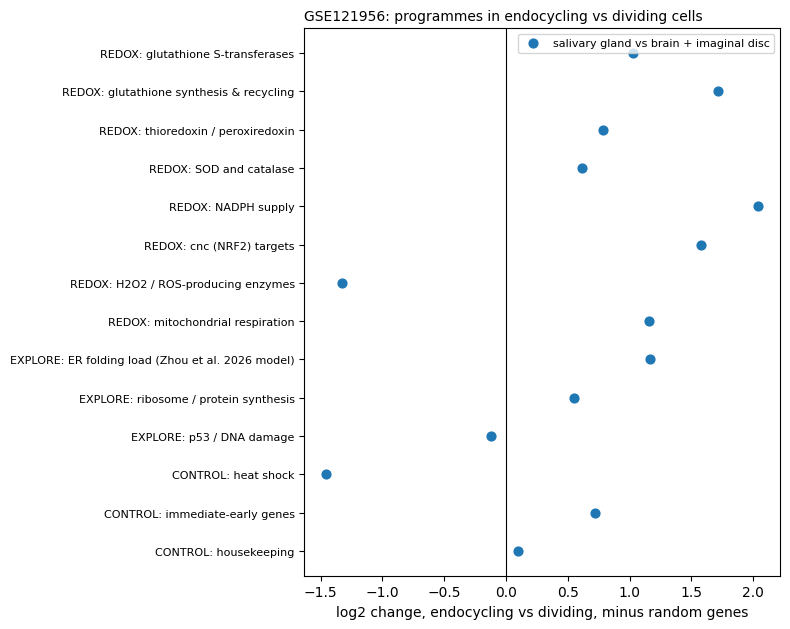

Saved to /content/drive/MyDrive/Colab Notebooks/route_d_salivary/GSE121956


In [ ]:
#@title Cell 6 - Gene by gene, chart and saving
genes = list(dict.fromkeys(g for n, v in PROGRAMMES.items() if not n.startswith("CONTROL") for g in v))
tab = pd.DataFrame({f"{t} vs {r}": (gmean[t] - gmean[r]).loc[genes] for t, r in CONTRASTS})
tab["mean_log2_change"] = tab.mean(axis=1)
tab["same_direction_all"] = (np.sign(tab.iloc[:, :len(CONTRASTS)]).nunique(axis=1) == 1)
tab["programme"] = [", ".join(n.split(": ")[1] for n, v in PROGRAMMES.items() if g in v) for g in genes]
for g in info.group.unique():
    tab[f"mean_{g}"] = gmean[g].loc[genes]
display(tab.sort_values("mean_log2_change").round(2))

fig, ax = plt.subplots(figsize=(8, 0.35 * len(PROGRAMMES) + 1.5))
names = list(PROGRAMMES)
for k, ct in enumerate(res.contrast.unique()):
    s = res[res.contrast == ct].set_index("programme").loc[names]
    y = np.arange(len(names)) + (k - (len(CONTRASTS) - 1) / 2) * 0.25
    ax.scatter(s.log2_change - s.random_median, y, label=ct, s=40)
ax.axvline(0, color="black", lw=0.8); ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("log2 change, endocycling vs dividing, minus random genes")
ax.set_title(f"{GSE}: programmes in endocycling vs dividing cells", loc="left", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(GDIR, "chart_programmes.png"), dpi=150); plt.show()
res.to_csv(os.path.join(GDIR, "programmes.csv"), index=False); tab.to_csv(os.path.join(GDIR, "genes.csv"))
print("Saved to", GDIR)